In [5]:
import pandas as pd 
df=pd.read_csv("NEW-Telco-Customer-Churn.csv")

print(df.head())
print(df.shape) # shows the number of rows and columns.

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
print(df.columns)
print(df.isnull().sum())

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [3]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce" # changes values that cannot be converted into numbers into missing values (NaN).
)

print(df["TotalCharges"].isnull().sum())

11


In [ ]:
df = df.dropna()
print(df.isnull().sum().sum())

# 0 mean no missing values 

0


In [ ]:
# check how many customers leave 
# we need : Exploratory Data Analysis (EDA) is the process of analyzing and 
# visualizing a dataset to understand its structure, 
# identify patterns, and discover relationships between variables.

import matplotlib.pyplot as plt

!pip install seaborn 
import seaborn as sns

print(df["Churn"].value_counts())
# how many customers stayed no and left yes 

You should consider upgrading via the 'C:\Users\nikita\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


Churn
No     5163
Yes    1869
Name: count, dtype: int64


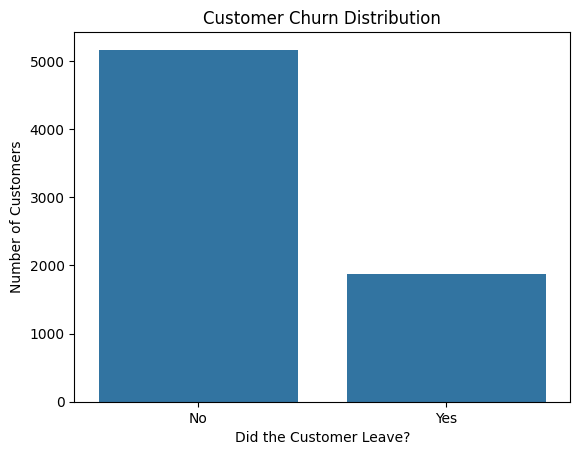

In [ ]:
sns.countplot(data=df, x="Churn")  # counts & display customers in each category 

plt.title("Customer Churn Distribution")
plt.xlabel("Did the Customer Leave?")
plt.ylabel("Number of Customers")

plt.show()

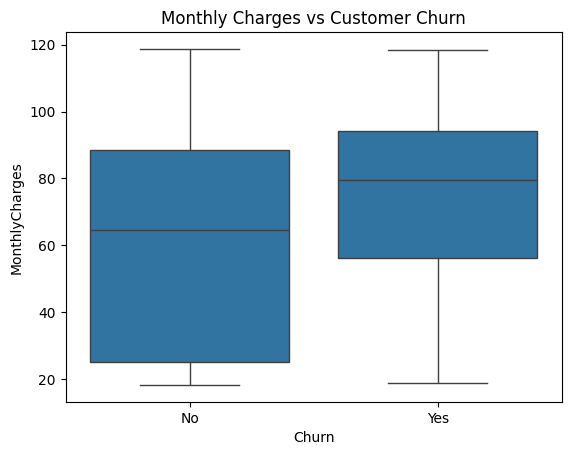

In [10]:
# compare the monthly charges 
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.show()

In [11]:
print(df["Churn"].value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [12]:
# convert target column into nos
df["Churn"] = df["Churn"].map({
    "No":0,
    "Yes":1
})

print(df["Churn"].head())

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64


In [ ]:
X= df.drop("Churn",axis=1)# axis=1 tells Pandas to drop a column rather than a row.
y=df["Churn"]

print("Features :",X.shape)
print("Target :",y.shape)

#Your dataset has 7,032 customers and 20 input columns.
# There are 7,032 target answers, one for each customer.

Features : (7032, 20)
Target : (7032,)


In [6]:
from sklearn.model_selection import train_test_split
# divides our dataset into training and testing parts.

X= df.drop("Churn",axis=1)# axis=1 tells Pandas to drop a column rather than a row.
y=df["Churn"]

X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size=0.2, # keeps 20% for testing and 80% for training.
    random_state=42,
    stratify =y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 20)
Testing data: (1409, 20)


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [7]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

print(categorical_columns)

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges'],
      dtype='object')


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train) # learns from training data 
X_test_encoded = preprocessor.transform(X_test) # applies that same conversion to the test data.

print("Encoded training data:", X_train_encoded.shape)
print("Encoded testing data:", X_test_encoded.shape)

Encoded training data: (5634, 10954)
Encoded testing data: (1409, 10954)


In [12]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,# Uses 100 Decision Trees
    random_state=42,
    class_weight="balanced" # Gives extra weight to the less common class
)

# Train the model
model.fit(X_train_encoded, y_train)# eaches the model using training data

print("Random Forest model training completed!")

Random Forest model training completed!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Predict churn for test customers
y_pred = model.predict(X_test_encoded)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7889125799573561

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [ ]:
Precision	When the model predicts a customer will leave, how often is it correct?	63%
Recall	    Of all customers who actually left, how many did the model find?	    50%
F1-score	A balance between precision and recall                                  56%
Accuracy	Percentage of all predictions that were correct	                        78.89%

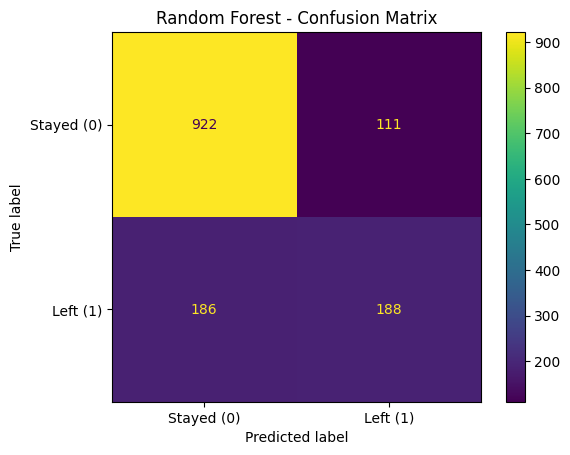

[[922 111]
 [186 188]]


In [ ]:
Your model's predictions
Rows = actual results · Columns = predicted results


Correctly stayed              False alarm
922                           111
True negatives                False positives


Missed churners               Correctly found churners
186                           188
False negatives               True positives
